In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [2]:
#parameters time unit = generation time
r_sa = 1.0
r_wa = 0.85 * r_sa
r_sb = 0.001 * r_sa
r_wb = 0.001 * r_wa

d_s = 0.002
d_w = 0.001
switch =1

m_s = 0.02
m_w = 0.01

mu = 1.1 * math.pow(10,-8)
K_a = math.pow(10,10)

tstep = 0.001
Tend = 300 #generation time ~2h. Tend / 12 = days
recordtime = 0.5

In [3]:
#functions
def d_sa(sa,sb,wa,wb):
    growth = r_sa*sa
    if (sa+wa)/K_a >= 1.0:
        dispersal = -d_s*sa*switch/(d_s*sa*switch+d_w*wa)*(r_sa*sa+r_wa*wa)
    else:
        dispersal = -d_s*sa
    migration = m_s*sb*(1.0-(sa+wa)/K_a)
    mutation = -mu*r_sa*sa + mu*r_wa*wa
    return growth + dispersal + migration + mutation

def d_wa(sa,sb,wa,wb):
    growth = r_wa*wa
    if (sa+wa)/K_a >= 1.0:
        dispersal = -d_w*wa/(d_s*sa*switch+d_w*wa)*(r_sa*sa+r_wa*wa)
    else:
        dispersal = -d_w*wa
    migration = m_w*wb*(1.0-(sa+wa)/K_a)
    mutation = mu*r_sa*sa - mu*r_wa*wa
    return growth + dispersal + migration + mutation

def d_sb(sa,sb,wa,wb):
    growth = r_sb*sb
    if (sa+wa)/K_a >= 1.0:
        dispersal = d_s*sa*switch/(d_s*sa*switch+d_w*wa)*(r_sa*sa+r_wa*wa)
    else:
        dispersal = d_s*sa
    migration = -m_s*sb*(1.0-(sa+wa)/K_a)
    mutation = -mu*r_sb*sb + mu*r_wb*wb
    return growth + dispersal + migration + mutation

def d_wb(sa,sb,wa,wb):
    growth = r_wb*wb
    if (sa+wa)/K_a >= 1.0:
        dispersal = d_w*wa/(d_s*sa*switch+d_w*wa)*(r_sa*sa+r_wa*wa)
    else:
        dispersal = d_w*wa
    migration = -m_w*wb*(1.0-(sa+wa)/K_a)
    mutation = mu*r_sb*sb - mu*r_wb*wb
    return growth + dispersal + migration + mutation

def mload_a(sa,sb,wa,wb):
    mutation = mu*r_sa*sa
    return mutation

def mload_b(sa,sb,wa,wb):
    mutation = mu*r_sb*sb
    return mutation
    

In [4]:
#variables and initial conditions.
time = 0
Nsa = 100000.0
Nsb = 10000000.0
Nwa = 0.0
Nwb = 0.0
timevector = np.zeros([])
savector = np.zeros([])
sbvector = np.zeros([])
wavector = np.zeros([])
wbvector = np.zeros([])
mutload_a = np.zeros([])
mutload_b = np.zeros([])

count = 0

#main loop
while time < Tend:
    #record data
    if time >= count*recordtime:
        timevector = np.append(timevector, time)
        savector = np.append(savector, Nsa)
        sbvector = np.append(sbvector, Nsb)
        wavector = np.append(wavector, Nwa)
        wbvector = np.append(wbvector, Nwb)
        mutload_a = np.append(mutload_a, mload_a(Nsa,Nsb,Nwa,Nwb))
        mutload_b = np.append(mutload_b, mload_b(Nsa,Nsb,Nwa,Nwb))
        count = count+1
        
    #update values
    delta_sa = d_sa(Nsa,Nsb,Nwa,Nwb)*tstep
    delta_sb = d_sb(Nsa,Nsb,Nwa,Nwb)*tstep
    delta_wa = d_wa(Nsa,Nsb,Nwa,Nwb)*tstep
    delta_wb = d_wb(Nsa,Nsb,Nwa,Nwb)*tstep

    Nsa = Nsa + delta_sa
    Nsb = Nsb + delta_sb
    Nwa = Nwa + delta_wa
    Nwb = Nwb + delta_wb
    time = time + tstep

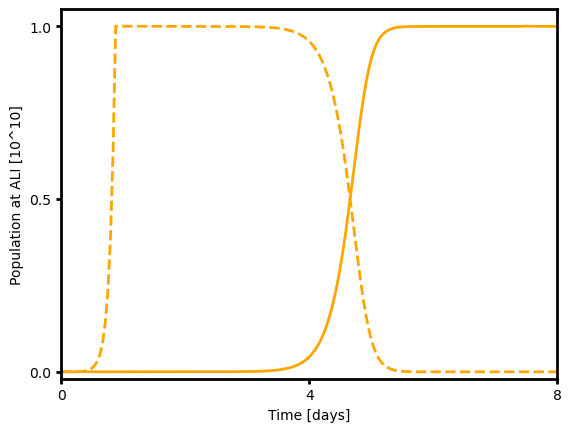

In [5]:
plt.rcParams['axes.linewidth'] = 2
plt.tick_params(axis='both',width=2)

plt.plot(timevector/12,wavector/math.pow(10,10),color='orange',linewidth =2.0)
plt.plot(timevector/12,savector/math.pow(10,10),color='orange',linewidth =2.0,linestyle="--")

plt.xlim([0,8])
plt.xticks([0,4,8])

plt.ylim([-0.02,1.05])
plt.yticks([0,0.5,1])

plt.xlabel("Time [days]")
plt.ylabel("Population at ALI [10^10]")

plt.show()
#plt.savefig("4state-ALI.png",dpi=600)

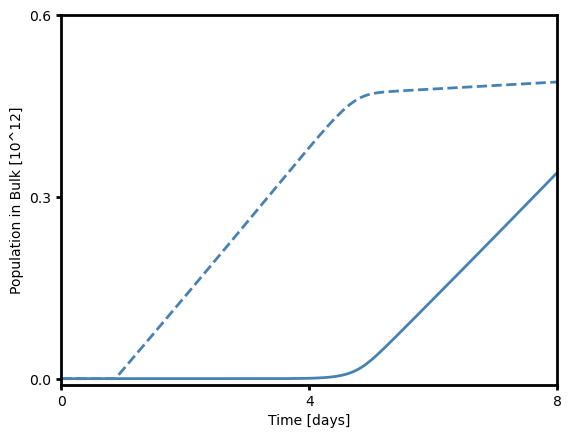

In [6]:
plt.rcParams['axes.linewidth'] = 2
plt.tick_params(axis='both',width=2)

plt.plot(timevector/12,wbvector/math.pow(10,12),color='steelblue',linewidth =2.0)
plt.plot(timevector/12,sbvector/math.pow(10,12),color='steelblue',linewidth =2.0,linestyle="--")

plt.xlim([0,8])
plt.xticks([0,4,8])

plt.ylim([-0.01,0.6])
plt.yticks([0,0.3,0.6])

plt.xlabel("Time [days]")
plt.ylabel("Population in Bulk [10^12]")

plt.show()
#plt.savefig("4state-Bulk.png",dpi=600)

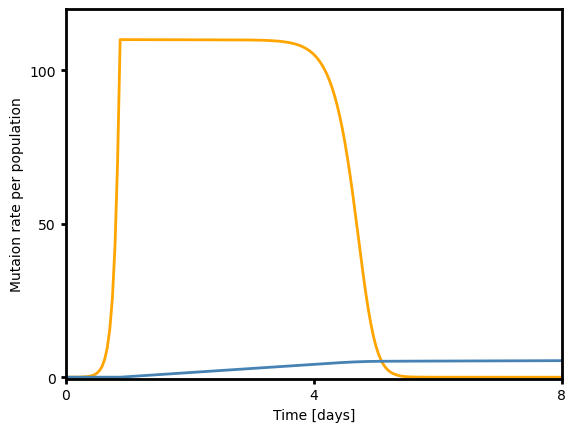

In [7]:
plt.rcParams['axes.linewidth'] = 2
plt.tick_params(axis='both',width=2)

plt.plot(timevector/12,mutload_a,color='orange',linewidth =2.0)
plt.plot(timevector/12,mutload_b,color='steelblue',linewidth =2.0)

plt.xlim([0,8])
plt.xticks([0,4,8])

plt.ylim([-0.5,120])
plt.yticks([0,50,100])

plt.xlabel("Time [days]")
plt.ylabel("Mutaion rate per population")

plt.show()
#plt.savefig("4state-mutation.png",dpi=600)